# Zadanie 1 – podstawy operacji na obrazach w Pythonie
Notebook pokazuje wczytanie obrazu lokalnie i zdalnie, jego wyświetlenie, zmianę rozdzielczości, 
konwersję do skali szarości, obrót oraz wypisanie macierzy pikseli. 

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

## Krok 1: wczytanie obrazu
Obraz jest wczytywany na dwa sposoby.
- lokalnie – cv2.imread czyta plik z dysku i zwraca tablicę numpy z wartościami pikseli. 
- zdalnie – urllib pobiera surowe bajty pliku z internetu, a imdecode rozpakowuje je z JPEG do macierzy pikseli, ze względu na to, że imread nie przyjmuje adresu URL. 
W obu przypadkach wynikiem jest trójwymiarowa tablica numpy w kolejności BGR: wysokość x szerokość x 3. 

(639, 960, 3)


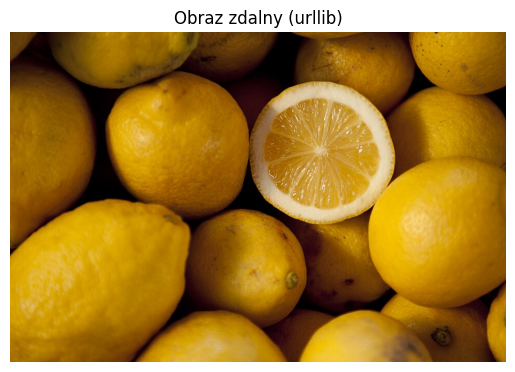

In [2]:
url = "https://thumb.wikimedia.org/wikipedia/commons/thumb/b/b8/Lemons_for_sale.JPG/960px-Lemons_for_sale.JPG?download"

req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(req) as odpowiedz:
    dane = odpowiedz.read()

tablica = np.asarray(bytearray(dane), dtype=np.uint8)
img_zdalny = cv2.imdecode(tablica, cv2.IMREAD_COLOR)

print(img_zdalny.shape)

plt.imshow(cv2.cvtColor(img_zdalny, cv2.COLOR_BGR2RGB))
plt.title("Obraz zdalny (urllib)")
plt.axis("off")
plt.show()

In [3]:
img = cv2.imread("lemon.jpeg")
print(type(img))
print(img.shape)

<class 'numpy.ndarray'>
(639, 960, 3)


## Krok 2: wyświetlanie
Obraz wyświetlany jest funkcją plt.imshow z biblioteki matplotlib. OpenCV wczytuje kanały w kolejności BGR, a matplotlib oczekuje RGB, dlatego najpierw wymagana jest konwersja obrazu przez cv2.cvtColor(img, cv2.COLOR_BGR2RGB). Bez konwersji kanały czerwony i niebieski są zamienione, więc kolory wyglądają błędnie (zamiast koloru żółtego są odcienie niebieskiego).


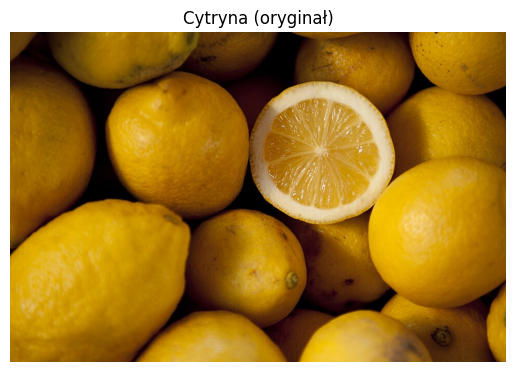

In [4]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.title("Cytryna (oryginał)")
plt.axis("off")
plt.show()

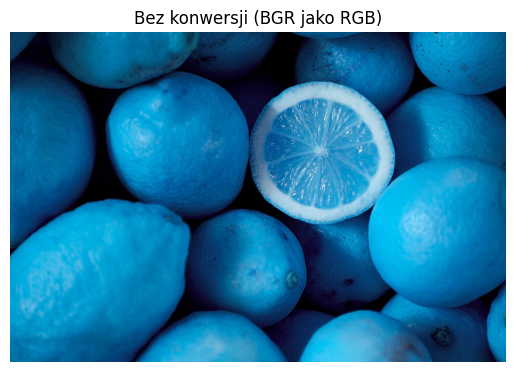

In [5]:
plt.imshow(img)
plt.title("Bez konwersji (BGR jako RGB)")
plt.axis("off")
plt.show()

## Krok 3: rozdzielczość i skala szarości
Rozdzielczość zmniejszona o 50% funkcją cv2.resize, która przyjmuje nowe wymiary w kolejności (szerokość, wysokość), podczas gdy shape zwraca (wysokość, szerokość, kanały). Wymiary obrazu zmieniły się z (639, 960, 3) na (319, 480, 3). Nowe wymiary są liczone przez int(...), który ucina część ułamkową aby liczba była całkowita – liczba pikseli musi być całkowita. Następnie obraz jest konwertowany do skali szarości przez cv2.cvtColor z flagą cv2.COLOR_BGR2GRAY. Wymiary zmieniły się na (319, 480). Trzeci wymiar zniknął, ponieważ w skali szarości piksel to jedna liczba, a nie trzy kanały. 

In [6]:
nowa_szerokosc = int(img.shape[1] * 0.5)
nowa_wysokosc = int(img.shape[0] * 0.5)

img_maly = cv2.resize(img, (nowa_szerokosc, nowa_wysokosc))
img_gray = cv2.cvtColor(img_maly, cv2.COLOR_BGR2GRAY)

print("Przed:", img.shape)
print("Po zmniejszeniu:", img_maly.shape)
print("Grayscale:", img_gray.shape)

Przed: (639, 960, 3)
Po zmniejszeniu: (319, 480, 3)
Grayscale: (319, 480)


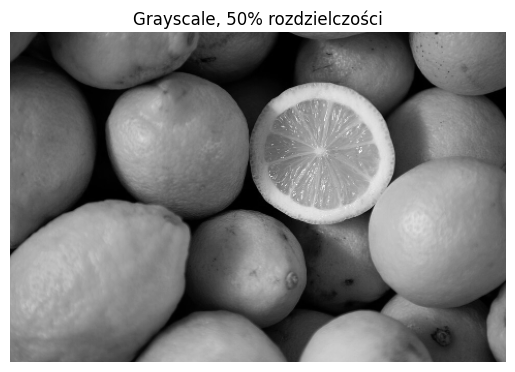

In [7]:
plt.imshow(img_gray, cmap="gray")
plt.title("Grayscale, 50% rozdzielczości")
plt.axis("off")
plt.show()

## Krok 4 i 5: obrót i wyświetlenie wyniku
Obraz w skali szarości jest obrócony o 90 stopni w prawo funkcją cv2.rotate z flagą cv2.ROTATE_90_CLOCKWISE. Wymiary zmieniły się z (319, 480) na (480, 319), ponieważ po obrocie wysokość i szerokość zamieniają się miejscami. Wynik jest wyświetlony funkcją plt.imshow z parametrem cmap="gray". Parametr jest potrzebny, ze względu na to że obraz ma tylko jeden kanał i bez niego matplotlib zastosowałby domyślną paletę kolorów zamiast skali szarości. 

In [8]:
img_obrocony = cv2.rotate(img_gray, cv2.ROTATE_90_CLOCKWISE)
print("Przed obrotem:", img_gray.shape)
print("Po obrocie:", img_obrocony.shape)

Przed obrotem: (319, 480)
Po obrocie: (480, 319)


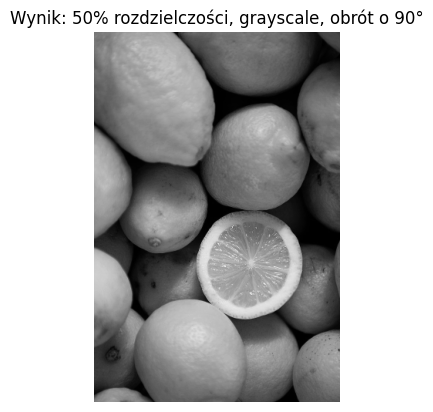

In [9]:
plt.imshow(img_obrocony, cmap="gray")
plt.title("Wynik: 50% rozdzielczości, grayscale, obrót o 90°")
plt.axis("off")
plt.show()

## Krok 6: macierz
Wypisywana jest macierz obrazu po wszystkich poprzednich operacjach. Macierz nie wyświetla się w całości ze względu na objętość, która przekracza kilkadziesiąt tysięcy wartości, dlatego ujawnione są tylko rogi z wielokropkami w środku. Typ danych macierzy to uint8, czyli 8-bitowa liczba całkowita bez znaku. Na 8 bitach można zapisać 256 wartości, więc każdy piksel ma wartość od 0 (czarny kolor) do 255 (maksymalna jasność), a zapisanie go zajmuje 1 bajt. Najmniejsza wartość w obrazie wynosi 0, a największa to 246, co wskazuje na to, że pełny zakres (0 - 255) jest dozwolony, ale obraz nie musi go w pełni wykorzystywać.

In [10]:
print(img_obrocony)
print("Typ danych:", img_obrocony.dtype)
print("Min:", img_obrocony.min(), "Max:", img_obrocony.max())

[[115 115 111 ...  59  58  62]
 [113 112 114 ...  60  60  60]
 [114 116 118 ...  63  62  60]
 ...
 [114 114 117 ...  88  89  87]
 [114 117 121 ...  89  86  84]
 [115 119 123 ...  81  79  79]]
Typ danych: uint8
Min: 0 Max: 246
